# Bike rental demand: exploration and first feature decisions

We forecast the next hour after the current hour finishes. This notebook explores pre-test data only. No hyperparameter tuning is performed. The final 90 days are held out.

In [1]:
from pathlib import Path
import sys
import json

root = Path.cwd().resolve()
while not (root / "model" / "src" / "bike_demand").is_dir():
    if root == root.parent:
        raise RuntimeError("Open this notebook inside the bikeRental project")
    root = root.parent
sys.path.insert(0, str(root / "model" / "src"))
from IPython.display import Image, display
from bike_demand.config import RAW_DATA_PATH
from bike_demand.data import load_hourly
from bike_demand.eda import run_eda
from bike_demand.features import build_features

## 1. Audit the timeline and freeze the split

Missing CSV cells and missing timestamps are different problems. Reindex to an hourly grid before shifting demand. An absent observation remains unknown, never automatically zero. Only timestamp coverage is audited globally; demand exploration uses the development period.

In [2]:
summary = run_eda()
summary

{'first_timestamp': '2011-01-01 00:00:00',
 'last_timestamp': '2012-12-31 23:00:00',
 'observed_rows': 17379,
 'expected_hourly_rows': 17544,
 'missing_timestamps': 165,
 'development_observed_rows': 15259,
 'development_missing_hours': 125,
 'test_start': '2012-10-03 00:00:00',
 'development_target_summary': {'count': 15259.0,
  'mean': 185.39078576577757,
  'std': 178.08092583223691,
  'min': 1.0,
  '25%': 39.0,
  '50%': 138.0,
  '75%': 275.0,
  'max': 977.0},
 'missing_values_in_observed_rows': {'instant': 0,
  'dteday': 0,
  'season': 0,
  'yr': 0,
  'mnth': 0,
  'hr': 0,
  'holiday': 0,
  'weekday': 0,
  'workingday': 0,
  'weathersit': 0,
  'temp': 0,
  'atemp': 0,
  'hum': 0,
  'windspeed': 0,
  'casual': 0,
  'registered': 0,
  'cnt': 0,
  'hour': 0,
  'weekday_name': 0,
  'month': 0},
 'development_weather_correlations': {'cnt': 1.0,
  'temp': 0.4352000244118904,
  'atemp': 0.42862816804258447,
  'hum': -0.32841530961010784,
  'windspeed': 0.09954071602072434},
 'peak_mean_hou

In [3]:
hourly = load_hourly(RAW_DATA_PATH)
development = hourly.loc[hourly.index < summary["test_start"]].copy()
development.dropna(subset=["cnt"]).head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
target_timestamp,,,,,,,,,,,,,,,,,
2011-01-01 00:00:00,1.0,2011-01-01,1.0,0.0,1.0,0.0,0.0,6.0,0.0,1.0,0.24,0.2879,0.81,0.0,3.0,13.0,16.0
2011-01-01 01:00:00,2.0,2011-01-01,1.0,0.0,1.0,1.0,0.0,6.0,0.0,1.0,0.22,0.2727,0.80,0.0,8.0,32.0,40.0
2011-01-01 02:00:00,3.0,2011-01-01,1.0,0.0,1.0,2.0,0.0,6.0,0.0,1.0,0.22,0.2727,0.80,0.0,5.0,27.0,32.0
2011-01-01 03:00:00,4.0,2011-01-01,1.0,0.0,1.0,3.0,0.0,6.0,0.0,1.0,0.24,0.2879,0.75,0.0,3.0,10.0,13.0
2011-01-01 04:00:00,5.0,2011-01-01,1.0,0.0,1.0,4.0,0.0,6.0,0.0,1.0,0.24,0.2879,0.75,0.0,0.0,1.0,1.0


## 2. Demand distribution and growth

Look for skew, unusually large values and changes over time. Daily means average available observations, so missing hours may affect them.

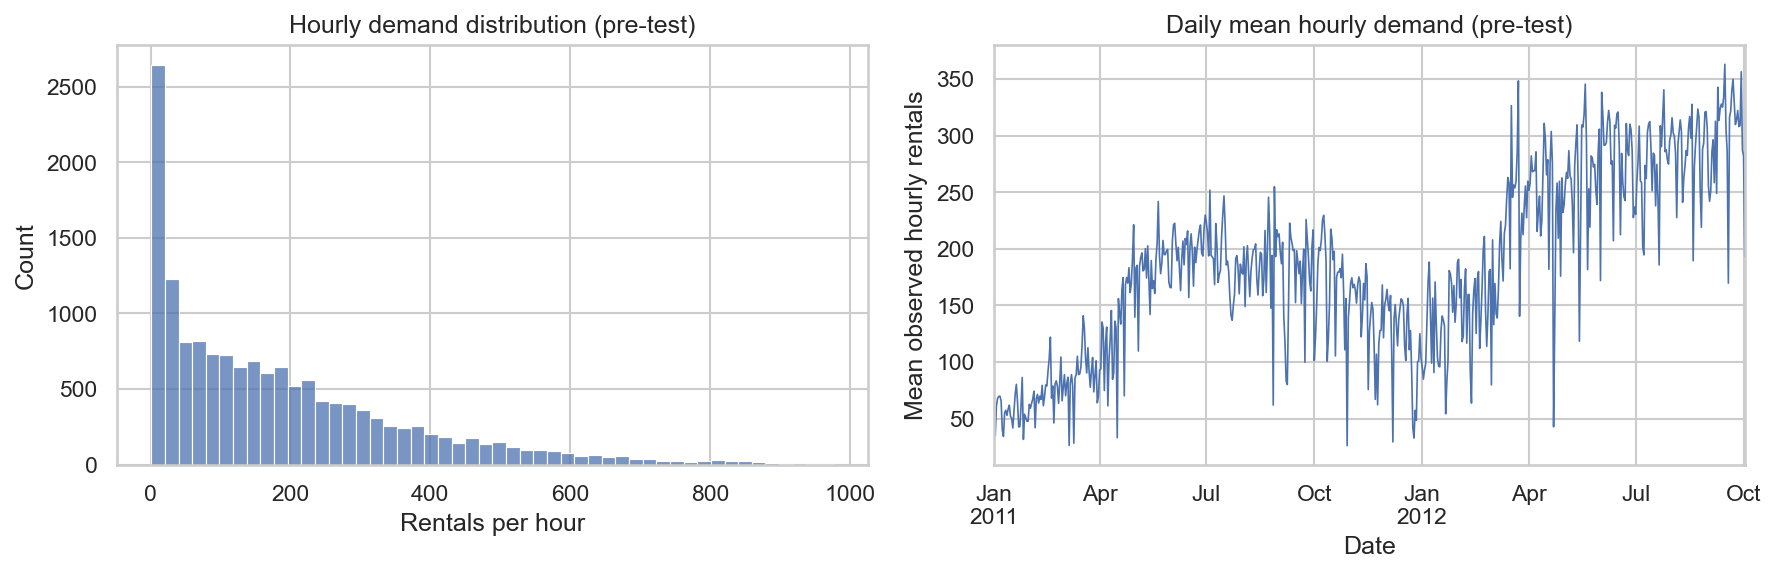

In [4]:
display(Image(filename=str(root / "outputs/figures/01_demand_distribution_and_trend.png")))

## 3. Weekday and hour heatmap

Compare commute periods with weekend daytime demand. Calendar features allow the models to distinguish these patterns. Cell values are means over observed pre-test hours.

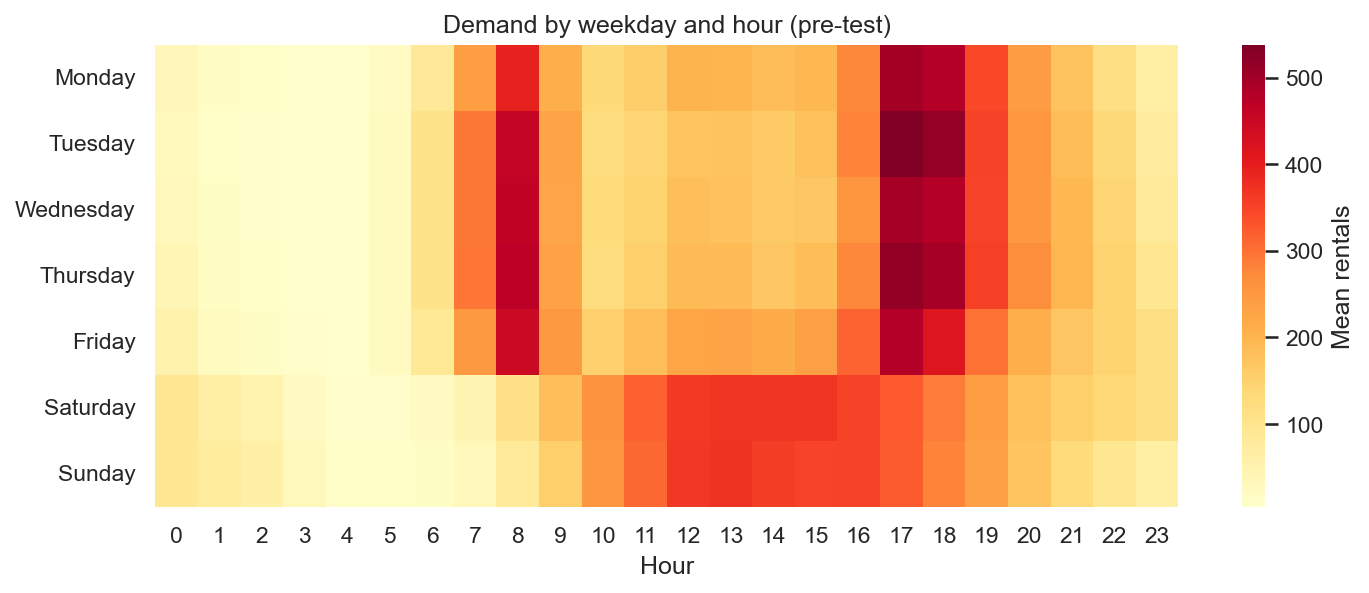

In [5]:
display(Image(filename=str(root / "outputs/figures/02_weekday_hour_heatmap.png")))

## 4. Temperature heatmap and demand relationship

Use the original normalized temperature scale: the archive README and current UCI web documentation disagree about its Celsius conversion. These plots describe same-hour observations. Association does not establish causation, and same-hour observed weather is not available for our forecast.

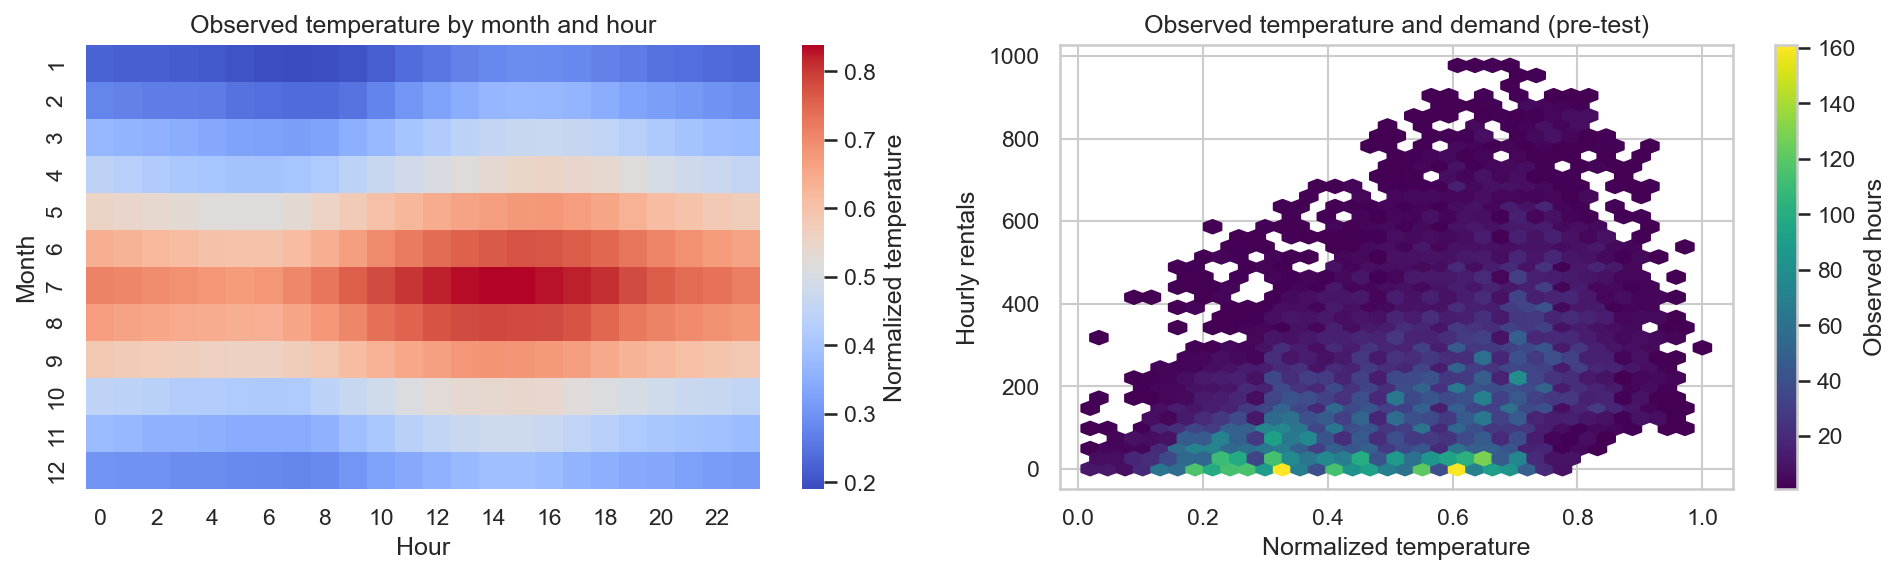

In [6]:
display(Image(filename=str(root / "outputs/figures/03_temperature_patterns.png")))

## 5. Working days and correlations

Pearson correlation misses nonlinear and conditional effects. Do not choose predictors solely from this matrix. Casual and registered demand are excluded because they sum to the target.

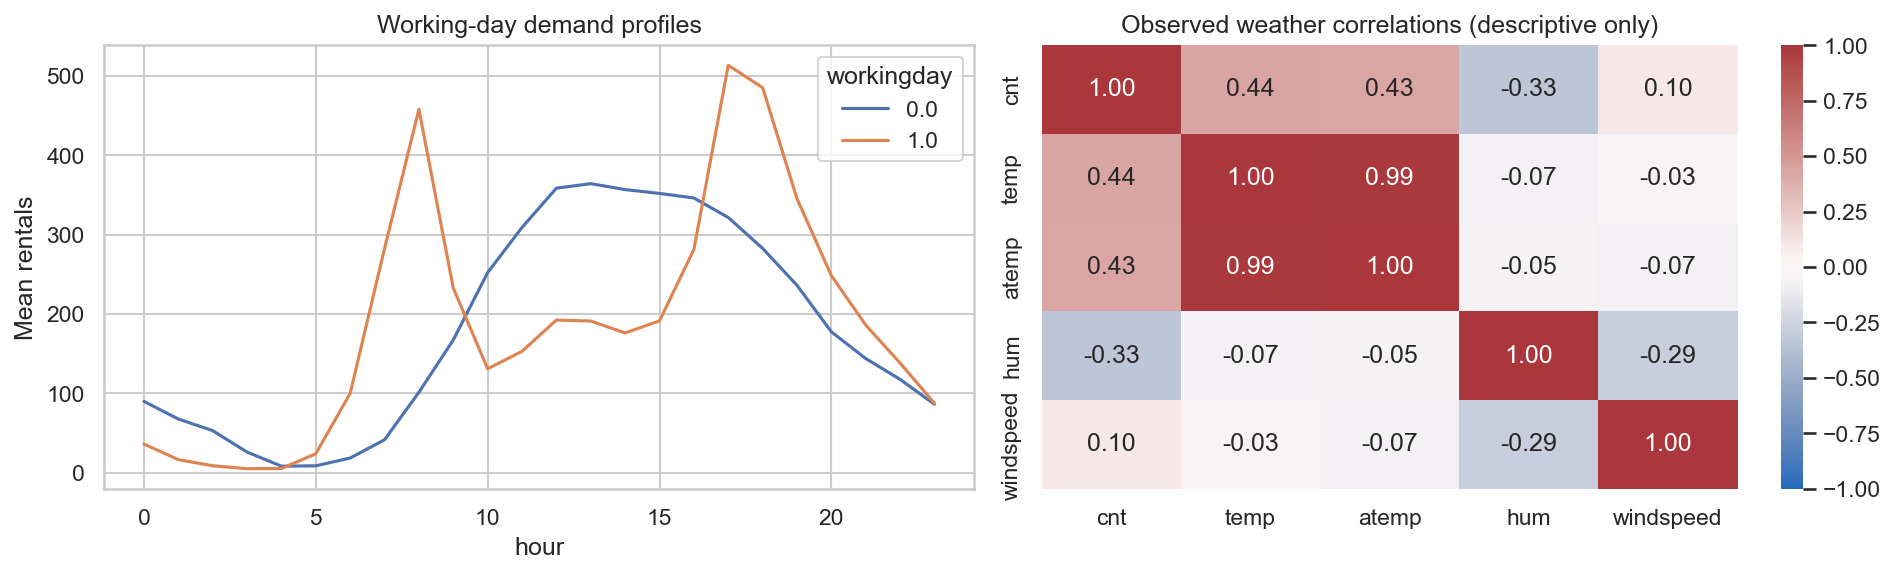

In [7]:
display(Image(filename=str(root / "outputs/figures/04_profiles_and_correlations.png")))

## 6. Missing timestamps

The reason for an absent hour is not established by this file. Keep it missing. Lag 24 must mean 24 elapsed hours, even across a gap. The dataset provides local date/hour labels without timezone offsets; daylight-saving ambiguity remains a limitation.

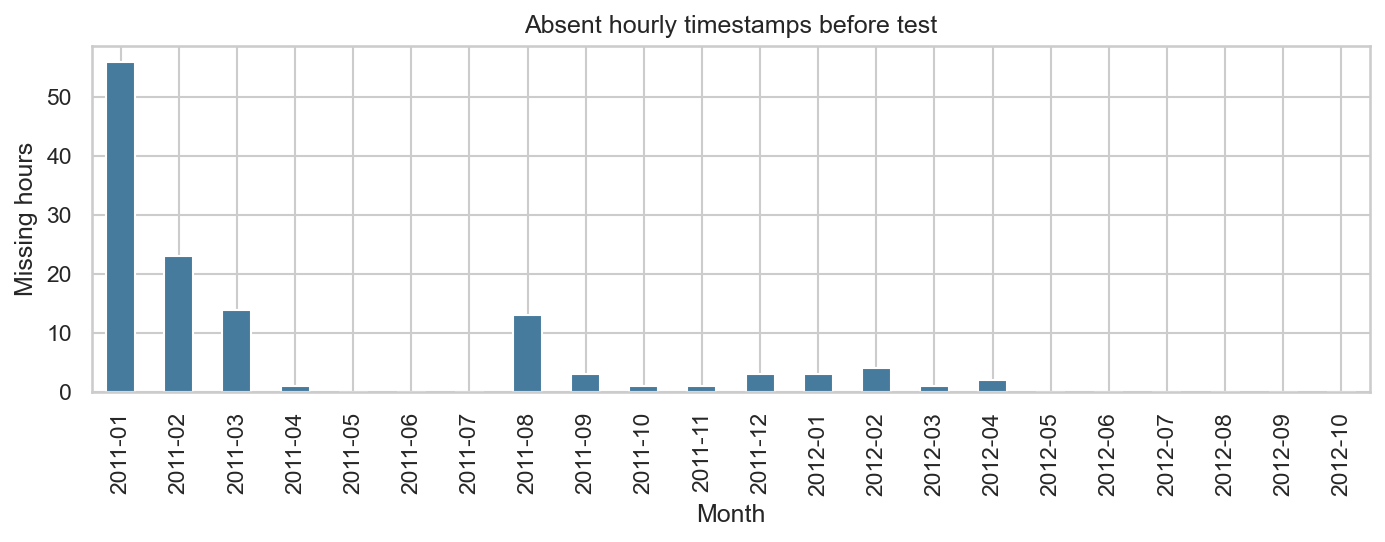

In [8]:
display(Image(filename=str(root / "outputs/figures/05_missing_hours.png")))

## 7. Initial feature set

Calendar: hour, weekday, month, holiday, working day, weekend, elapsed days and cyclical encodings. History: lags 1/2/24/48/168 and means/std over the previous 24/168 hours. All rolling windows exclude the target. Full-window missing statistics are imputed within training folds.

This is a domain-informed starting set, not an optimized subset. Correlated calendar encodings can later be evaluated through ablation. No target-hour weather or target components are included. Holiday flags are assumed to be available from a calendar in production.

In [9]:
features = build_features(development)
features.tail()

,hour,weekday,month,is_weekend,holiday,workingday,days_since_start,hour_sin,hour_cos,weekday_sin,...,month_cos,demand_lag_1,demand_lag_2,demand_lag_24,demand_lag_48,demand_lag_168,demand_mean_24,demand_std_24,demand_mean_168,demand_std_168
target_timestamp,,,,,,,,,,,,,,,,,,,,,
2012-10-02 19:00:00,19,1,10,0,0.0,1.0,640.791667,-0.965926,0.258819,0.781831,...,-1.836970e-16,687.0,715.0,516.0,257.0,539.0,192.458333,199.462752,295.363095,251.128147
2012-10-02 20:00:00,20,1,10,0,0.0,1.0,640.833333,-0.866025,0.500000,0.781831,...,-1.836970e-16,395.0,687.0,262.0,194.0,425.0,187.416667,192.330991,294.505952,250.536646
2012-10-02 21:00:00,21,1,10,0,0.0,1.0,640.875000,-0.707107,0.707107,0.781831,...,-1.836970e-16,306.0,395.0,218.0,123.0,297.0,189.250000,193.280209,293.797619,250.333635
2012-10-02 22:00:00,22,1,10,0,0.0,1.0,640.916667,-0.500000,0.866025,0.781831,...,-1.836970e-16,289.0,306.0,207.0,91.0,188.0,192.208333,194.280161,293.750000,250.333783
2012-10-02 23:00:00,23,1,10,0,0.0,1.0,640.958333,-0.258819,0.965926,0.781831,...,-1.836970e-16,240.0,289.0,105.0,57.0,98.0,193.583333,194.506045,294.059524,250.234374


## 8. First training run

Run `python model/train.py` from the project root after inspecting this notebook. It compares last-hour and weekly baselines, Ridge, Random Forest and histogram gradient boosting with fixed settings. Three successive 28-day validation blocks precede the held-out test; training expands each time. Features for later validation hours may use earlier observed validation demand, matching rolling one-hour-ahead prediction.

The saved model is provisional. Do not use final-test results to choose features or parameters. No GridSearchCV yet.